<a href="https://colab.research.google.com/github/YazGonzalezHerrera/Simulaci-n-II/blob/main/Movimiento%20Browniano%20con%20Deriva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Movimiento Browniano con Deriva**

**Ejercicio**

Encuentre la probabilidad de que el movimiento browniano con parámetro deriva, $\mu = 0.6$, y varianza, $\sigma^2 = 0.25$, tome valores entre 1 y 3 al tiempo $t = 4$.

*Solución analítica*

$X_t = 0.6t + 0.5B_t$

Sustituyendo $t = 4$

$P(1<X_4<3) = P(1<0.6(4)+0.5B_4<3)$

$P(1<X_4<3) = P(1<2.4+0.5B_4<3)$

$P(1<X_4<3) = P(-1.4<0.5B_4<0.6)$

$P(1<X_4<3) = P(-2.8<B_4<1.2)$

$P(1<X_4<3) = \int\limits_{- 2.8}^{1.2}\frac{1}{\sqrt{2(4)\pi }}e^{- \frac{x^2}{8}}dx$

$P(1<X_4<3) = 0.645$

Analíticamente, la probabilidad del Movimiento Browniano es de 64.5%

Ahora, por medio de simulación, obtenemos las probables trayectorias del Movimiento Browniano:

In [21]:
import random as r
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

In [7]:
def brown(T,n):
  lista = []
  dt=np.sqrt(T/n)
  w_0=0
  for i in range(1,n):
    dw=r.gauss(0,1)
    w_1=w_0+dw*dt
    lista.append(w_1)
    w_0=w_1
  return lista

In [11]:
def deriva(mu,sigma,T,n):
  t = np.linspace(0,T,n)
  B = np.array(brown(T,n))
  X = mu*t + sigma*B
  return t,X

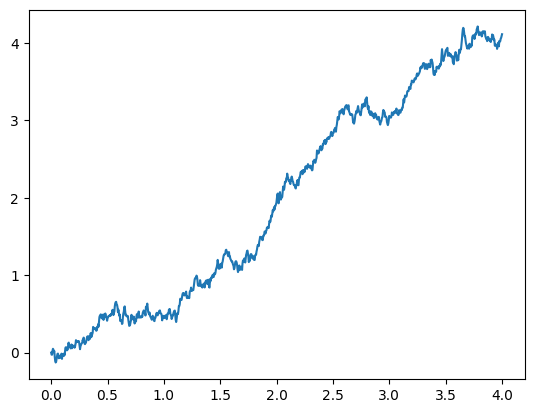

In [17]:
def deriva_corr(mu, sigma, T, n):
    t = np.linspace(0, T, n)
    B = np.array([0] + brown(T, n))
    X = mu * t + sigma * B
    return t, X

t, X = deriva_corr(0.6, 0.5, 4, 1000)
plt.plot(t, X)

Ahora, por simulación de Monte Carlo, obtenemos la probabilidad

In [22]:
# Parámetros del ejercicio
mu = 0.6
sigma = 0.5
T = 4

# Cálculo teórico
mean = mu * T
std_dev = sigma * np.sqrt(T)

prob_te = stats.norm.cdf(3, loc=mean, scale=std_dev) - stats.norm.cdf(1, loc=mean, scale=std_dev)
print(f"Probabilidad Teórica: {prob_te:.6f} ({prob_te * 100:.4f}%)")

Probabilidad Teórica: 0.644990 (64.4990%)


In [26]:
# Simulación de Monte Carlo
n = 10000
pasos = 100
valores_finales = []

for _ in range(n):
    _, X_path = deriva_corr(mu, sigma, T, pasos)
    valores_finales.append(X_path[-1])

valores_finales = np.array(valores_finales)
# Contamos cuántas trayectorias terminan entre 1 y 3
exitos = np.sum((valores_finales > 1) & (valores_finales < 3))
prob_simulada = exitos / n

print(f"Probabilidad por simulación: {prob_simulada:.6f} ({prob_simulada * 100:.4f}%)")

Probabilidad por simulación: 0.653300 (65.3300%)
